#Sentiment Analysis
importing libraries
sentiment score calculation
sentiment classification
sentiment distribution
statistical testing

In [1]:
#importing libraries
import pandas as pd
import numpy as np
import re 
import matplotlib.pyplot as plt
import os
from scipy.stats import pearsonr
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu
from itertools import combinations 
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import statsmodels.api as sm
for file in os.listdir():
    if file.endswith("xlsx"):
        print(file)
!pip install vaderSentiment
!pip install scikit-posthocs
import scikit_posthocs as sp
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
#loading feature engineered datasets
gea_preprocessed = pd.read_excel("Gea_Preprocessed_All_Languages.xlsx")
pelagos_preprocessed = pd.read_excel("Pelagos_Preprocessed_All_Languages.xlsx")
gea = pd.read_excel("Gea_Feature_Engineering.xlsx")
pelagos = pd.read_excel("Pelagos_Feature_Engineering.xlsx")
gea_preprocessed_english = pd.read_excel("Gea_Preprocessed_English.xlsx")
pelagos_preprocessed_english = pd.read_excel("Pelagos_Preprocessed_English.xlsx")
print ("Gea preprocessed columns:")
print(gea_preprocessed.columns.tolist())
print ("\nPelagos preprocessed columns:")
print(pelagos_preprocessed.columns.tolist())

Gea_Preprocessed_English.xlsx
Pelagos_Reviews_2022_2026_Combined.xlsx
Gea_Preprocessed_All_Languages.xlsx
Pelagos_Preprocessed_All_Languages.xlsx
Gea_Reviews_2022_2026_Combined.xlsx
Pelagos_Preprocessed_English.xlsx
Pelagos_Feature_Engineering.xlsx
Gea_Feature_Engineering.xlsx
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Gea preprocessed columns:
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', '

In [2]:
print("Gea text columns:")
for col in gea_preprocessed.columns:
    if "text" in col.lower() or "review" in col.lower():
        print(col)
print("\nSample Gea Review_Text:")
print(gea_preprocessed["Review_Text"].head(10))

Gea text columns:
Review Site
Review Date
Review Title
Review
Review Link
Review ID
Review_Text
Review_Length
Short_Review

Sample Gea Review_Text:
0    Excellent. Good: staff  location    Bad: we di...
1    Of course the views are to die for! Room was v...
2    Outstanding Of course the views are to die for...
3    exceptionnel Good: vue incroyable   piscine   ...
4    Magical This hotel is magical, in terms of its...
5    bello pero conflictivo el tema de la habitació...
6    Best ,amazing,don’t. Miss it it’s a great hote...
7    Perfect 4 day stay in Santorini My wife and I ...
8    Fantastic!! Good: We loved everything about ou...
9    Magical stay Really lovely hotel. A place to r...
Name: Review_Text, dtype: object


In [3]:
gea_preprocessed = pd.read_excel("Gea_Preprocessed_English.xlsx")
pelagos_preprocessed = pd.read_excel("Pelagos_Preprocessed_English.xlsx")

print("Gea:", gea_preprocessed.shape)
print("Clean_Text exists:", "Clean_Text" in gea_preprocessed.columns)

print("Pelagos:", pelagos_preprocessed.shape)
print("Clean_Text exists:", "Clean_Text" in pelagos_preprocessed.columns)

Gea: (202, 32)
Clean_Text exists: True
Pelagos: (667, 30)
Clean_Text exists: True


In [4]:
#inspecting text for sentiment analysis 

print("Gea")
print("Total reviews:", len(gea_preprocessed))
print("Missing Clean_Text:", gea_preprocessed["Clean_Text"].isna().sum())
print("Available Clean_Text:", gea_preprocessed["Clean_Text"].notna().sum())

print("\nPelagos")
print("Total reviews:", len(pelagos_preprocessed))
print("Missing Clean_Text:", pelagos_preprocessed["Clean_Text"].isna().sum())
print("Available Clean_Text:", pelagos_preprocessed["Clean_Text"].notna().sum())

print("\nGea sample")
print(gea_preprocessed[["Review_Text", "Clean_Text"]].dropna().head())
print("\nPelagos sample")
print(pelagos_preprocessed[["Review_Text", "Clean_Text"]].dropna().head())

Gea
Total reviews: 202
Missing Clean_Text: 0
Available Clean_Text: 202

Pelagos
Total reviews: 667
Missing Clean_Text: 0
Available Clean_Text: 667

Gea sample
                                         Review_Text  \
0  Excellent. Good: staff  location    Bad: we di...   
1  Of course the views are to die for! Room was v...   
2  Outstanding Of course the views are to die for...   
3  Magical This hotel is magical, in terms of its...   
4  Best ,amazing,don’t. Miss it it’s a great hote...   

                                          Clean_Text  
0  excellent good staff location bad we didn t re...  
1  of course the views are to die for room was ve...  
2  outstanding of course the views are to die for...  
3  magical this hotel is magical in terms of its ...  
4  best amazing don t miss it it s a great hotel ...  

Pelagos sample
                                         Review_Text  \
0  The best way to experience Santorini… This hot...   
1  Worth every penny. The staff were amazing. 

In [5]:
print("Gea sample:")
print(gea[["Review_Text"]].head(10))
print("\nPelagos sample:")
print(pelagos[["Review_Text"]].head(10))

Gea sample:
                                         Review_Text
0  Excellent. Good: staff  location    Bad: we di...
1  Of course the views are to die for! Room was v...
2  Outstanding Of course the views are to die for...
3  exceptionnel Good: vue incroyable   piscine   ...
4  Magical This hotel is magical, in terms of its...
5  bello pero conflictivo el tema de la habitació...
6  Best ,amazing,don’t. Miss it it’s a great hote...
7  Perfect 4 day stay in Santorini My wife and I ...
8  Fantastic!! Good: We loved everything about ou...
9  Magical stay Really lovely hotel. A place to r...

Pelagos sample:
                                         Review_Text
0  The best way to experience Santorini… This hot...
1  Worth every penny. The staff were amazing. The...
2                                        非常滿意，環境非常好👍
3  Excelente atención desde antes de llegar, adem...
4                                       Good: 很美的日落景
5                  Walkability: Many steps and steep
6  Good: Beautifu

In [6]:
#Sentiment Analysis using Vader

analyzer = SentimentIntensityAnalyzer()

#Calculating compound sentiment score 
gea_preprocessed["Sentiment_Score"] = (
    gea_preprocessed["Clean_Text"]
    .astype(str)
    .apply(lambda x: analyzer.polarity_scores(x)["compound"])
 )
pelagos_preprocessed["Sentiment_Score"] = (
    pelagos_preprocessed["Clean_Text"]
    .astype(str)
    .apply(lambda x: analyzer.polarity_scores(x)["compound"])
 )
print("Gea sentiment scores:")
print(gea_preprocessed[["Clean_Text", "Sentiment_Score"]].head())
    
print("Pelagos sentiment scores:")
print(pelagos_preprocessed[["Clean_Text", "Sentiment_Score"]].head())
    

Gea sentiment scores:
                                          Clean_Text  Sentiment_Score
0  excellent good staff location bad we didn t re...           0.6808
1  of course the views are to die for room was ve...           0.2230
2  outstanding of course the views are to die for...           0.7083
3  magical this hotel is magical in terms of its ...           0.9451
4  best amazing don t miss it it s a great hotel ...           0.9851
Pelagos sentiment scores:
                                          Clean_Text  Sentiment_Score
0  the best way to experience santorini… this hot...           0.9975
1  worth every penny. the staff were amazing. the...           0.8074
2                  walkability: many steps and steep           0.0000
3  good: beautiful hotel! the staff was incredibl...           0.5519
4  pretty much flawless the service, amenities, f...           0.9661


In [7]:
#Clasifying sentiment into Positive, Neutral and Negative
def classify_sentiment(score):
    if score>= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

gea_preprocessed["Sentiment_Category"] = (
    gea_preprocessed["Sentiment_Score"].apply(classify_sentiment)
)
pelagos_preprocessed["Sentiment_Category"] = (
    pelagos_preprocessed["Sentiment_Score"].apply(classify_sentiment)
)
print("Gea:")
print(gea_preprocessed["Sentiment_Category"].value_counts())
print("\nPelagos:")
print(pelagos_preprocessed["Sentiment_Category"].value_counts())

Gea:
Sentiment_Category
Positive    196
Neutral       5
Negative      1
Name: count, dtype: int64

Pelagos:
Sentiment_Category
Positive    617
Negative     26
Neutral      24
Name: count, dtype: int64


In [8]:
#Calculating sentiment distribution percentages 
gea_sentiment_pct = (
    gea_preprocessed["Sentiment_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
pelagos_sentiment_pct = (
    pelagos_preprocessed["Sentiment_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
print("Gea sentiment percentages:")
print(gea_sentiment_pct)
print("\nPelagos sentiment percentages:")
print(pelagos_sentiment_pct)

Gea sentiment percentages:
Sentiment_Category
Positive    97.03
Neutral      2.48
Negative     0.50
Name: proportion, dtype: float64

Pelagos sentiment percentages:
Sentiment_Category
Positive    92.5
Negative     3.9
Neutral      3.6
Name: proportion, dtype: float64


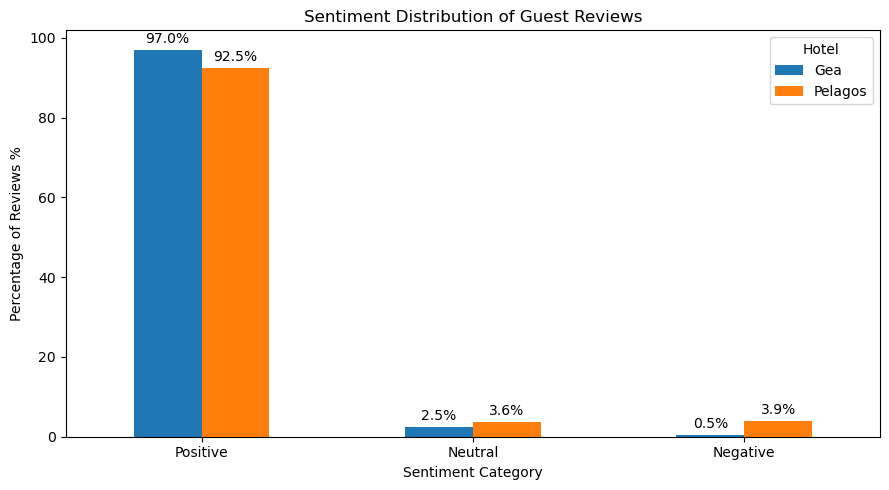

In [9]:
#Creating comparison table
sentiment_comparison = pd.DataFrame({
    "Gea": gea_sentiment_pct,
    "Pelagos": pelagos_sentiment_pct
}).reindex(["Positive", "Neutral", "Negative"])

ax = sentiment_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sentiment Distribution of Guest Reviews")
plt.xlabel("Sentiment Category")
plt.ylabel("Percentage of Reviews %")
plt.xticks(rotation=0)
plt.legend(title="Hotel")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

In [10]:
#Sentiment score by guest rating
gea_rating_sentiment = (
    gea_preprocessed
    .groupby("Rating")["Sentiment_Score"]
    .agg(['count', "mean"])
    .round(3)
)
pelagos_rating_sentiment = (
    pelagos_preprocessed
    .groupby("Rating")["Sentiment_Score"]
    .agg(['count', "mean"])
    .round(3)
)
print("Gea sentiment by rating ")
print(gea_rating_sentiment)

print("\nPelagos sentiment by rating")
print(pelagos_rating_sentiment)

Gea sentiment by rating 
        count   mean
Rating              
1.0         1  0.981
3.0         2 -0.453
3.5         1  0.681
4.0        18  0.705
4.5         3  0.910
5.0       169  0.881

Pelagos sentiment by rating
        count   mean
Rating              
1.0        21 -0.177
2.0        10  0.260
3.0        21  0.440
3.5         3  0.911
4.0        38  0.810
4.5        13  0.814
4.6         3  0.820
4.8         2  0.918
5.0       554  0.839


In [11]:
# Correlation between guest rating and sentiment score

gea_corr = gea_preprocessed[
["Rating", "Sentiment_Score"]
].corr().loc["Rating", "Sentiment_Score"]

pelagos_corr = pelagos_preprocessed[
["Rating", "Sentiment_Score"]
].corr().loc["Rating", "Sentiment_Score"]

print("Correlation between Rating and Sentiment Score")
print(f"Gea: {gea_corr:.3f}")
print(f"Pelagos: {pelagos_corr:.3f}")

Correlation between Rating and Sentiment Score
Gea: 0.351
Pelagos: 0.536


In [12]:
#Removing missing values 
analyzer = SentimentIntensityAnalyzer()

# Recreate sentiment scores
gea_preprocessed["Sentiment_Score"] = (
gea_preprocessed["Clean_Text"]
.astype(str)
.apply(lambda x: analyzer.polarity_scores(x)["compound"])
)

pelagos_preprocessed["Sentiment_Score"] = (
pelagos_preprocessed["Clean_Text"]
.astype(str)
.apply(lambda x: analyzer.polarity_scores(x)["compound"])
)

# Keep only Rating and Sentiment Score
gea_test = gea_preprocessed[
["Rating", "Sentiment_Score"]
].dropna()

pelagos_test = pelagos_preprocessed[
["Rating", "Sentiment_Score"]
].dropna()

# Pearson correlation
gea_r, gea_p = pearsonr(
gea_test["Rating"],
gea_test["Sentiment_Score"]
)

pelagos_r, pelagos_p = pearsonr(
pelagos_test["Rating"],
pelagos_test["Sentiment_Score"]
)

print("Gea")
print(f"Pearson r: {gea_r:.3f}")
print(f"p-value: {gea_p:.4f}")

print("\nPelagos")
print(f"Pearson r: {pelagos_r:.3f}")
print(f"p-value: {pelagos_p:.4f}")

Gea
Pearson r: 0.351
p-value: 0.0000

Pelagos
Pearson r: 0.536
p-value: 0.0000


In [13]:
print("Gea:")
print("Guest_Region" in gea.columns)
print("\nPelagos:")
print("Guest_Region" in gea.columns)

Gea:
True

Pelagos:
True


In [14]:
print("Gea feature engineering rows:", len(gea))
print("Gea sentiment rows:", len(gea_preprocessed))

print("\nPelagos feature engineering rows:", len(pelagos))
print("Pelagos sentiment rows:", len(pelagos_preprocessed))

Gea feature engineering rows: 249
Gea sentiment rows: 202

Pelagos feature engineering rows: 878
Pelagos sentiment rows: 667


In [15]:
print("Gea featue data:", gea.shape)
print("Gea sentiment data:", gea_preprocessed.shape)
print("\nPelagos featue data:", gea.shape)
print("Pelagos sentiment data:", pelagos_preprocessed.shape)

Gea featue data: (249, 35)
Gea sentiment data: (202, 34)

Pelagos featue data: (249, 35)
Pelagos sentiment data: (667, 32)


In [16]:
print("GEA")
print("Feature rows:", len(gea))
print("Unique Review IDs:", gea["Review ID"].nunique())
print("Missing Review IDs:", gea["Review ID"].isna().sum())

print("\nGEA PREPROCESSED")
print("Sentiment rows:", len(gea_preprocessed))
print("Unique Review IDs:", gea_preprocessed["Review ID"].nunique())
print("Missing Review IDs:", gea_preprocessed["Review ID"].isna().sum())

print("\nPELAGOS")
print("Feature rows:", len(pelagos))
print("Unique Review IDs:", pelagos["Review ID"].nunique())
print("Missing Review IDs:", pelagos["Review ID"].isna().sum())

print("\nPELAGOS PREPROCESSED")
print("Sentiment rows:", len(pelagos_preprocessed))
print("Unique Review IDs:", pelagos_preprocessed["Review ID"].nunique())
print("Missing Review IDs:", pelagos_preprocessed["Review ID"].isna().sum())

GEA
Feature rows: 249
Unique Review IDs: 249
Missing Review IDs: 0

GEA PREPROCESSED
Sentiment rows: 202
Unique Review IDs: 202
Missing Review IDs: 0

PELAGOS
Feature rows: 878
Unique Review IDs: 878
Missing Review IDs: 0

PELAGOS PREPROCESSED
Sentiment rows: 667
Unique Review IDs: 667
Missing Review IDs: 0


In [17]:
# Merge Guest Region into sentiment datasets using Review ID

gea_sentiment_region = gea_preprocessed.merge(
gea[["Review ID", "Guest_Region"]],
on="Review ID",
how="left"
)

pelagos_sentiment_region = pelagos_preprocessed.merge(
pelagos[["Review ID", "Guest_Region"]],
on="Review ID",
how="left"
)

print("Gea merged rows:", len(gea_sentiment_region))
print("Gea missing regions:", gea_sentiment_region["Guest_Region"].isna().sum())

print("\nPelagos merged rows:", len(pelagos_sentiment_region))
print("Pelagos missing regions:", pelagos_sentiment_region["Guest_Region"].isna().sum())

Gea merged rows: 202
Gea missing regions: 0

Pelagos merged rows: 667
Pelagos missing regions: 0


In [18]:
#Average sentiment score by Guest Region
gea_region_sentiment = (
gea_sentiment_region
.groupby("Guest_Region")["Sentiment_Score"]
.agg(["count", "mean"])
.round(3)
.sort_values("count", ascending=False)
)

pelagos_region_sentiment = (
pelagos_sentiment_region
.groupby("Guest_Region")["Sentiment_Score"]
.agg(["count", "mean"])
.round(3)
.sort_values("count", ascending=False)
)

print("GEA - Sentiment by Guest Region")
print(gea_region_sentiment)

print("\nPELAGOS - Sentiment by Guest Region")
print(pelagos_region_sentiment)

GEA - Sentiment by Guest Region
               count   mean
Guest_Region               
Unknown          139  0.845
North America     30  0.934
Europe            12  0.949
Asia               7  0.742
Middle East        6  0.755
Oceania            4  0.693
South America      4  0.807

PELAGOS - Sentiment by Guest Region
               count   mean
Guest_Region               
Unknown          486  0.761
North America    112  0.855
Europe            35  0.926
Asia              13  0.721
Oceania           10  0.787
Middle East        7  0.633
South America      3  0.673
Africa             1  0.477


In [19]:
# Exclude Unknown region for H2 analysis

gea_h2 = gea_sentiment_region[
gea_sentiment_region["Guest_Region"] != "Unknown"
].copy()

pelagos_h2 = pelagos_sentiment_region[
pelagos_sentiment_region["Guest_Region"] != "Unknown"
].copy()

print("GEA")
print("Reviews with known region:", len(gea_h2))
print(gea_h2["Guest_Region"].value_counts())

print("\nPELAGOS")
print("Reviews with known region:", len(pelagos_h2))
print(pelagos_h2["Guest_Region"].value_counts())

GEA
Reviews with known region: 63
Guest_Region
North America    30
Europe           12
Asia              7
Middle East       6
South America     4
Oceania           4
Name: count, dtype: int64

PELAGOS
Reviews with known region: 181
Guest_Region
North America    112
Europe            35
Asia              13
Oceania           10
Middle East        7
South America      3
Africa             1
Name: count, dtype: int64


In [20]:
gea_groups = [
    group["Sentiment_Score"].dropna().values
    for region, group in gea_h2.groupby("Guest_Region")
    if len(group["Sentiment_Score"].dropna()) >=2
]
gea_h, gea_p = kruskal(*gea_groups)
print("Gea Kruskal Wallis Test")
print(f"H-statistics: {gea_h:.3f}")
print(f"p-value: {gea_p:.4f}")

pelagos_groups = [
    group["Sentiment_Score"].dropna().values
    for region, group in pelagos_h2.groupby("Guest_Region")
    if len(group["Sentiment_Score"].dropna()) >=2
]
pelagos_h, pelagos_p = kruskal(*pelagos_groups)
print("Pelagos Kruskal Wallis Test")
print(f"H-statistics: {pelagos_h:.3f}")
print(f"p-value: {pelagos_p:.4f}")

Gea Kruskal Wallis Test
H-statistics: 11.954
p-value: 0.0354
Pelagos Kruskal Wallis Test
H-statistics: 13.143
p-value: 0.0221


In [21]:
gea_dunn = sp.posthoc_dunn(
gea_h2,
val_col="Sentiment_Score",
group_col="Guest_Region",
p_adjust="bonferroni"
)

print("Gea Dunn's Post-hoc Test")
display(gea_dunn)


# PELAGOS removing regions with fewer than 2 reviews
pelagos_counts = pelagos_h2["Guest_Region"].value_counts()
valid_pelagos_regions = pelagos_counts[pelagos_counts >= 2].index

pelagos_h2_dunn = pelagos_h2[
pelagos_h2["Guest_Region"].isin(valid_pelagos_regions)
].copy()

pelagos_dunn = sp.posthoc_dunn(
pelagos_h2_dunn,
val_col="Sentiment_Score",
group_col="Guest_Region",
p_adjust="bonferroni"
)

print("\nPelagos Dunn's Post-hoc Test")
display(pelagos_dunn)

Gea Dunn's Post-hoc Test


,Asia,Europe,Middle East,North America,Oceania,South America
Asia,1.000000,0.231143,1.0,0.152789,1.000000,1.0
Europe,0.231143,1.000000,1.0,1.000000,0.913664,1.0
Middle East,1.000000,1.000000,1.0,1.000000,1.000000,1.0
North America,0.152789,1.000000,1.0,1.000000,0.872529,1.0
Oceania,1.000000,0.913664,1.0,0.872529,1.000000,1.0
South America,1.000000,1.000000,1.0,1.000000,1.000000,1.0



Pelagos Dunn's Post-hoc Test


,Asia,Europe,Middle East,North America,Oceania,South America
Asia,1.000000,0.274046,1.000000,1.000000,1.0,1.000000
Europe,0.274046,1.000000,0.137797,1.000000,1.0,0.460957
Middle East,1.000000,0.137797,1.000000,0.796815,1.0,1.000000
North America,1.000000,1.000000,0.796815,1.000000,1.0,1.000000
Oceania,1.000000,1.000000,1.000000,1.000000,1.0,1.000000
South America,1.000000,0.460957,1.000000,1.000000,1.0,1.000000


# Topic Service Attributes Analysis
identifying service attributes(staff, service, cleanliness, rooms, facilities, location, food, compare attributes with sentiment/satisfaction)


In [22]:
print("Gea columns:")
for col in gea.columns:
    print(col)

print("\nPelagos columns:")
for col in pelagos.columns:
    print(col)

Gea columns:
Hotel
Review Site
Revinate Collected Date
Review Date
Rating
Review Title
Review
Subrating: Cleanliness
Subrating: Location
Subrating: Rooms
Subrating: Service
Subrating: Value
Subrating: Sleep Quality
Recommended
Response
Review Link
Ticket
External ID
Language
Author
Author Location
Review ID
Response Submitted Date
Response Posted Date
Unnamed: 24
Unnamed: 25
Unnamed: 26
Review_Text
Review_Length
Short_Review
Satisfaction_Category
Review_Word_Count
Location_Clean
Guest_Country
Guest_Region

Pelagos columns:
Hotel
Review Site
Revinate Collected Date
Review Date
Rating
Review Title
Review
Subrating: Cleanliness
Subrating: Location
Subrating: Rooms
Subrating: Service
Subrating: Value
Subrating: Sleep Quality
Recommended
Response
Review Link
Ticket
External ID
Language
Author
Author Location
Review ID
Response Submitted Date
Response Posted Date
Review_Text
Language_Final
Review_Length
Clean_Text
Short_Review
Satisfaction_Category
Review_Word_Count
Location_Clean
Guest_Coun

In [23]:
# Defining service attributes for H1
service_attributes = {
    "Staff": ["staff", "team", "employee", "reception", "receptionist"],
    "Service": ["service", "hospitality", "helpful", "professional"],
    "Cleanliness": ["clean", "cleanliness", "dirty", "spotless"],
    "Room": ["room", "suite", "bed", "bedroom"],
    "Facilities": ["pool", "spa", "gym", "facility", "facilities"],
    "Location": ["location", "view", "area", "distance"],
    "Food": ["food", "breakfast", "restaurant", "dinner", "lunch"]
}

def create_attribute_features(df):
    df = df.copy()

    for attribute, keywords in service_attributes.items():
        pattern = r"\b(?:" + "|".join(map(re.escape, keywords)) + r")\b"

        df[attribute + "_Mention"] = (
             df["Clean_Text"]
             .fillna("")
             .str.contains(pattern, case=False, regex=True)
             .astype(int)
        )

    return df


gea_h1 = create_attribute_features(gea_preprocessed)
pelagos_h1 = create_attribute_features(pelagos_preprocessed)

attribute_columns = [
    "Staff_Mention",
    "Service_Mention",
    "Cleanliness_Mention",
    "Room_Mention",
    "Facilities_Mention",
    "Location_Mention",
   "Food_Mention"
]

print("GEA - Attribute Mentions")
print(gea_h1[attribute_columns].sum())

print("\nPELAGOS - Attribute Mentions")
print(pelagos_h1[attribute_columns].sum())

GEA - Attribute Mentions
Staff_Mention          138
Service_Mention         98
Cleanliness_Mention     26
Room_Mention            67
Facilities_Mention      47
Location_Mention        93
Food_Mention           116
dtype: int64

PELAGOS - Attribute Mentions
Staff_Mention          349
Service_Mention        281
Cleanliness_Mention     74
Room_Mention           187
Facilities_Mention     155
Location_Mention       288
Food_Mention           284
dtype: int64


In [24]:
def attribute_satisfaction_summary(df, attribute_columns):
    results = []

    for col in attribute_columns:
        mentioned = df[df[col] == 1]["Rating"].dropna()
        not_mentioned = df[df[col] == 0]["Rating"].dropna()

        results.append({
            "Attribute": col.replace("_Mention", ""),
            "Mention_Count": len(mentioned),
            "Mean_Rating_When_Mentioned": mentioned.mean(),
            "Mean_Rating_When_Not_Mentioned": not_mentioned.mean(),
            "Difference": mentioned.mean() - not_mentioned.mean()
        })

    return pd.DataFrame(results).round(3)


gea_attribute_results = attribute_satisfaction_summary(
     gea_h1, attribute_columns
)

pelagos_attribute_results = attribute_satisfaction_summary(
        pelagos_h1, attribute_columns
)

print("GEA - Service Attributes and Guest Satisfaction")
display(gea_attribute_results)

print("\nPELAGOS - Service Attributes and Guest Satisfaction")
display(pelagos_attribute_results)

GEA - Service Attributes and Guest Satisfaction


,Attribute,Mention_Count,Mean_Rating_When_Mentioned,Mean_Rating_When_Not_Mentioned,Difference
0,Staff,131,4.866,4.817,0.049
1,Service,93,4.962,4.748,0.215
2,Cleanliness,25,4.800,4.858,-0.058
3,Room,64,4.781,4.885,-0.103
4,Facilities,46,4.815,4.861,-0.046
5,Location,89,4.820,4.876,-0.056
6,Food,109,4.858,4.841,0.017



PELAGOS - Service Attributes and Guest Satisfaction


,Attribute,Mention_Count,Mean_Rating_When_Mentioned,Mean_Rating_When_Not_Mentioned,Difference
0,Staff,349,4.706,4.671,0.035
1,Service,281,4.636,4.728,-0.092
2,Cleanliness,74,4.669,4.692,-0.023
3,Room,186,4.539,4.748,-0.209
4,Facilities,155,4.575,4.724,-0.149
5,Location,288,4.727,4.660,0.067
6,Food,284,4.706,4.677,0.028


In [25]:
def test_attribute_effects(df, attribute_columns):
    results = []

    for col in attribute_columns:
        mentioned = df.loc[df[col] == 1, "Rating"].dropna()
        not_mentioned = df.loc[df[col] == 0, "Rating"].dropna()

        stat, p = mannwhitneyu(
            mentioned,
            not_mentioned,
            alternative="two-sided"
        )

        results.append({
            "Attribute": col.replace("_Mention", ""),
            "Mentioned_N": len(mentioned),
            "Not_Mentioned_N": len(not_mentioned),
            "Mean_Mentioned": mentioned.mean(),
            "Mean_Not_Mentioned": not_mentioned.mean(),
            "Difference": mentioned.mean() - not_mentioned.mean(),
            "U_Statistic": stat,
            "P_Value": p,
            "Significant": "Yes" if p < 0.05 else "No"
         })

    return pd.DataFrame(results).round(4)


gea_h1_tests = test_attribute_effects(gea_h1, attribute_columns)
pelagos_h1_tests = test_attribute_effects(pelagos_h1, attribute_columns)

print("Gea H1 Statistical Tests")
display(gea_h1_tests)

print("\nPelagos H1 Statistical Tests")
display(pelagos_h1_tests)

Gea H1 Statistical Tests


,Attribute,Mentioned_N,Not_Mentioned_N,Mean_Mentioned,Mean_Not_Mentioned,Difference,U_Statistic,P_Value,Significant
0,Staff,131,63,4.8664,4.8175,0.0490,4400.0,0.1998,No
1,Service,93,101,4.9624,4.7475,0.2148,5483.5,0.0005,Yes
2,Cleanliness,25,169,4.8000,4.8580,-0.0580,2219.5,0.4846,No
3,Room,64,130,4.7812,4.8846,-0.1034,3896.0,0.2178,No
4,Facilities,46,148,4.8152,4.8615,-0.0463,3207.5,0.3109,No
5,Location,89,105,4.8202,4.8762,-0.0560,4529.0,0.5280,No
6,Food,109,85,4.8578,4.8412,0.0166,4548.0,0.7097,No



Pelagos H1 Statistical Tests


,Attribute,Mentioned_N,Not_Mentioned_N,Mean_Mentioned,Mean_Not_Mentioned,Difference,U_Statistic,P_Value,Significant
0,Staff,349,316,4.7060,4.6709,0.0351,55549.5,0.8000,No
1,Service,281,384,4.6359,4.7284,-0.0924,51707.5,0.1579,No
2,Cleanliness,74,591,4.6689,4.6919,-0.0230,21629.5,0.8148,No
3,Room,186,479,4.5387,4.7478,-0.2091,39502.0,0.0005,Yes
4,Facilities,155,510,4.5748,4.7241,-0.1493,36738.0,0.0405,Yes
5,Location,288,377,4.7271,4.6605,0.0666,53342.5,0.5532,No
6,Food,284,381,4.7056,4.6772,0.0285,53306.5,0.6173,No


In [26]:
def add_h1_correction_and_effect_size(results_df, original_df, attribute_columns):
    results = results_df.copy()

    # Holm correction for multiple comparisons
    reject, p_adjusted, _, _ = multipletests(
        results["P_Value"],
        alpha=0.05,
        method="holm"
    )

    results["Adjusted_P_Value"] = p_adjusted
    results["Significant_Adjusted"] = np.where(
    reject, "Yes", "No"
    )

    # Rank-biserial correlation as effect size
    effect_sizes = []

    for col in attribute_columns:
        mentioned = original_df.loc[
            original_df[col] == 1, "Rating"
        ].dropna()

        not_mentioned = original_df.loc[
            original_df[col] == 0, "Rating"
        ].dropna()

        U = mannwhitneyu(
            mentioned,
            not_mentioned,
            alternative="two-sided"
        ).statistic

        n1 = len(mentioned)
        n2 = len(not_mentioned)

        r_rb = (2 * U) / (n1 * n2) - 1
        effect_sizes.append(r_rb)

    results["Rank_Biserial_r"] = effect_sizes

    return results.round(4)


gea_h1_final = add_h1_correction_and_effect_size(
    gea_h1_tests,
    gea_h1,
    attribute_columns
)

pelagos_h1_final = add_h1_correction_and_effect_size(
        pelagos_h1_tests,
        pelagos_h1,
        attribute_columns
)

print("GEA - FINAL H1 RESULTS")
display(
    gea_h1_final[
        [
            "Attribute",
            "Difference",
            "P_Value",
            "Adjusted_P_Value",
            "Significant_Adjusted",
            "Rank_Biserial_r"
        ]
     ]
)

print("\nPELAGOS - FINAL H1 RESULTS")
display(
    pelagos_h1_final[
        [
            "Attribute",
            "Difference",
            "P_Value",
            "Adjusted_P_Value",
            "Significant_Adjusted",
            "Rank_Biserial_r"
        ]
     ]
)

GEA - FINAL H1 RESULTS


,Attribute,Difference,P_Value,Adjusted_P_Value,Significant_Adjusted,Rank_Biserial_r
0,Staff,0.0490,0.1998,1.0000,No,0.0663
1,Service,0.2148,0.0005,0.0035,Yes,0.1676
2,Cleanliness,-0.0580,0.4846,1.0000,No,0.0507
3,Room,-0.1034,0.2178,1.0000,No,-0.0635
4,Facilities,-0.0463,0.3109,1.0000,No,-0.0577
5,Location,-0.0560,0.5280,1.0000,No,-0.0307
6,Food,0.0166,0.7097,1.0000,No,-0.0182



PELAGOS - FINAL H1 RESULTS


,Attribute,Difference,P_Value,Adjusted_P_Value,Significant_Adjusted,Rank_Biserial_r
0,Staff,0.0351,0.8000,1.0000,No,0.0074
1,Service,-0.0924,0.1579,0.7895,No,-0.0416
2,Cleanliness,-0.0230,0.8148,1.0000,No,-0.0109
3,Room,-0.2091,0.0005,0.0035,Yes,-0.1133
4,Facilities,-0.1493,0.0405,0.2430,No,-0.0705
5,Location,0.0666,0.5532,1.0000,No,-0.0174
6,Food,0.0285,0.6173,1.0000,No,-0.0147


#H2 Satisfaction drivers by guest origin/region

In [27]:
#inspecting country and region variables 
print("Gea columns:")
print(gea.columns.tolist())
print("\nPelagos columns:")
print(pelagos.columns.tolist())

Gea columns:
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Review_Text', 'Review_Length', 'Short_Review', 'Satisfaction_Category', 'Review_Word_Count', 'Location_Clean', 'Guest_Country', 'Guest_Region']

Pelagos columns:
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'R

In [28]:
# guest region distribution
print("Gea_Guest_Regions")
print(gea["Guest_Region"].value_counts(dropna=False))

print("\nGea_Percentages")
print(gea["Guest_Region"]
      .value_counts(normalize=True, dropna=False)
      .mul(100)
      .round(2)

     )
print("\n" + "="*50)
print("\nPelagos_Guest_Regions")
print(pelagos["Guest_Region"].value_counts(dropna=False))

print("\nPelagos_Percentages")
print(pelagos["Guest_Region"]
      .value_counts(normalize=True, dropna=False)
      .mul(100)
      .round(2)
     )

Gea_Guest_Regions
Guest_Region
Unknown          155
North America     32
Europe            29
Asia              11
South America     11
Middle East        7
Oceania            4
Name: count, dtype: int64

Gea_Percentages
Guest_Region
Unknown          62.25
North America    12.85
Europe           11.65
Asia              4.42
South America     4.42
Middle East       2.81
Oceania           1.61
Name: proportion, dtype: float64


Pelagos_Guest_Regions
Guest_Region
Unknown          634
North America    115
Europe            63
Asia              32
South America     14
Oceania           10
Middle East        9
Africa             1
Name: count, dtype: int64

Pelagos_Percentages
Guest_Region
Unknown          72.21
North America    13.10
Europe            7.18
Asia              3.64
South America     1.59
Oceania           1.14
Middle East       1.03
Africa            0.11
Name: proportion, dtype: float64


In [29]:
#original guest countries
print("Gea_Guest_Countries")
print(gea["Guest_Country"].value_counts(dropna=False).to_string())
print("\n" + "="*60)

print("Pleagos_Guest_Countries")
print(pelagos["Guest_Country"].value_counts(dropna=False).to_string())

Gea_Guest_Countries
Guest_Country
Unknown                   155
United States              29
United Kingdom              9
Brazil                      8
Germany                     6
France                      5
Argentina                   3
Australia                   3
India                       3
Japan                       3
Hong Kong                   2
United Arab Emirates        2
Portugal                    2
Israel                      2
Italy                       2
British Virgin Islands      1
New Zealand                 1
South Korea                 1
Mexico                      1
Austria                     1
Romania                     1
Ireland                     1
Switzerland                 1
Sri Lanka                   1
Thailand                    1
Turkey                      1
Iraq                        1
Canada                      1
Luxembourg                  1
Jordan                      1

Pleagos_Guest_Countries
Guest_Country
Unknown                 633

In [30]:
# Will be keeping only reviews with a known guest region
gea_h2 = gea[
gea["Guest_Region"].notna() &
(gea["Guest_Region"] != "Unknown")
].copy()

pelagos_h2 = pelagos[
pelagos["Guest_Region"].notna() &
(pelagos["Guest_Region"] != "Unknown")
].copy()


# Checking sample sizes
print("Gea")
print("Total reviews:", len(gea))
print("Reviews included in H2:", len(gea_h2))
print("Reviews excluded due to unknown origin:", len(gea) - len(gea_h2))

print("\nGea_regions_included:")
print(gea_h2["Guest_Region"].value_counts())


print("\n" + "="*55)


print("\nPelagos")
print("Total reviews:", len(pelagos))
print("Reviews included in H2:", len(pelagos_h2))
print("Reviews excluded due to unknown origin:", len(pelagos) - len(pelagos_h2))

print("\nPelagos_regions_included:")
print(pelagos_h2["Guest_Region"].value_counts())

Gea
Total reviews: 249
Reviews included in H2: 94
Reviews excluded due to unknown origin: 155

Gea_regions_included:
Guest_Region
North America    32
Europe           29
Asia             11
South America    11
Middle East       7
Oceania           4
Name: count, dtype: int64


Pelagos
Total reviews: 878
Reviews included in H2: 244
Reviews excluded due to unknown origin: 634

Pelagos_regions_included:
Guest_Region
North America    115
Europe            63
Asia              32
South America     14
Oceania           10
Middle East        9
Africa             1
Name: count, dtype: int64


In [31]:
#Retaining regions with  n >= 10
Min_Region_N = 10

gea_region_counts = gea_h2["Guest_Region"].value_counts()
pelagos_region_counts = pelagos_h2["Guest_Region"].value_counts()

gea_valid_regions = gea_region_counts[
gea_region_counts >= Min_Region_N
].index

pelagos_valid_regions = pelagos_region_counts[
pelagos_region_counts >= Min_Region_N
].index


# Creation of datasets for H2 analysis
gea_h2_test = gea_h2[
gea_h2["Guest_Region"].isin(gea_valid_regions)
].copy()

pelagos_h2_test = pelagos_h2[
pelagos_h2["Guest_Region"].isin(pelagos_valid_regions)
].copy()


print("Gea_RegionsH2:")
print(gea_h2_test["Guest_Region"].value_counts())

print("\nGea H2 testing sample:", len(gea_h2_test))


print("\n" + "="*55)


print("\nPelagos_RegionsH2:")
print(pelagos_h2_test["Guest_Region"].value_counts())

print("\nPelagos H2 testing sample:", len(pelagos_h2_test))

Gea_RegionsH2:
Guest_Region
North America    32
Europe           29
Asia             11
South America    11
Name: count, dtype: int64

Gea H2 testing sample: 83


Pelagos_RegionsH2:
Guest_Region
North America    115
Europe            63
Asia              32
South America     14
Oceania           10
Name: count, dtype: int64

Pelagos H2 testing sample: 234


In [32]:
#Satisfaction by Guest Region
gea_region_satisfaction = (
    gea_h2_test
    .groupby("Guest_Region")["Rating"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean", ascending=False)

)
print("Gea_Satisfaction_by_guest_region")
print(gea_region_satisfaction)

pelagos_region_satisfaction = (
    pelagos_h2_test
    .groupby("Guest_Region")["Rating"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean", ascending=False)

)

print("Pelagos_Satisfaction_by_guest_region")
print(pelagos_region_satisfaction)

Gea_Satisfaction_by_guest_region
               count  mean  median   std
Guest_Region                            
North America     32  4.84     5.0  0.39
Europe            29  4.52     5.0  1.10
Asia              11  4.36     5.0  1.38
South America     11  4.18     4.0  0.90
Pelagos_Satisfaction_by_guest_region
               count  mean  median   std
Guest_Region                            
North America    115  4.86    5.00  0.47
South America     14  4.72    5.00  0.54
Europe            63  4.44    5.00  0.96
Asia              32  4.42    5.00  1.06
Oceania           10  4.05    4.25  1.07


In [33]:
def kruskal_by_region(df, hotel_name):
    groups = []

    for region in df["Guest_Region"].unique():
        ratings = df.loc[
            df["Guest_Region"] == region,
            "Rating"
        ].dropna()

        groups.append(ratings)

    h_stat, p_value = kruskal(*groups)

    print(f"{hotel_name} — Kruskal-Wallis Test")
    print(f"H statistic: {h_stat:.4f}")
    print(f"P-value: {p_value:.4f}")

    if p_value < 0.05:
        print("Result: Significant difference between guest regions")
    else:
        print("Result: No Significant difference between guest regions")
    print("-" * 55)

kruskal_by_region(gea_h2_test, "Gea")
kruskal_by_region(pelagos_h2_test, "Pelagos")

Gea — Kruskal-Wallis Test
H statistic: 7.1085
P-value: 0.0685
Result: No Significant difference between guest regions
-------------------------------------------------------
Pelagos — Kruskal-Wallis Test
H statistic: 25.0777
P-value: 0.0000
Result: Significant difference between guest regions
-------------------------------------------------------


In [34]:
results = []

regions = pelagos_h2_test["Guest_Region"].unique()

for region1, region2 in combinations(regions, 2):

    group1 = pelagos_h2_test.loc[
        pelagos_h2_test["Guest_Region"] == region1,
        "Rating"
    ].dropna()

    group2 = pelagos_h2_test.loc[
        pelagos_h2_test["Guest_Region"] == region2,
        "Rating"
    ].dropna()

    u_stat, p_value = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    results.append({
        "Region_1": region1,
        "Region_2": region2,
        "U_Statistic": u_stat,
        "P_Value": p_value
    })


pelagos_posthoc = pd.DataFrame(results)

# Holm correction for multiple comparisons
pelagos_posthoc["Adjusted_P_Value"] = multipletests(
    pelagos_posthoc["P_Value"],
    method="holm"
)[1]

pelagos_posthoc["Significant_Adjusted"] = (
    pelagos_posthoc["Adjusted_P_Value"] < 0.05
)

pelagos_posthoc = pelagos_posthoc.sort_values(
    "Adjusted_P_Value"
)

print("Pelagos — Pairwise_Regional_Comparisons")
print(pelagos_posthoc.round(4).to_string(index=False))

Pelagos — Pairwise_Regional_Comparisons
     Region_1      Region_2  U_Statistic  P_Value  Adjusted_P_Value  Significant_Adjusted
       Europe North America       2681.0   0.0001            0.0008                  True
North America       Oceania        863.0   0.0001            0.0008                  True
         Asia North America       1331.0   0.0006            0.0047                  True
South America       Oceania         97.5   0.0772            0.5405                 False
North America South America        925.5   0.1490            0.8941                 False
         Asia       Oceania        199.0   0.2133            0.8941                 False
       Europe       Oceania        392.5   0.1649            0.8941                 False
         Asia        Europe       1001.5   0.9571            1.0000                 False
       Europe South America        386.5   0.4071            1.0000                 False
         Asia South America        192.5   0.3924           

In [35]:
#satisfaction drivers column
print("Gea H2 columns:")
print(gea_h2_test.columns.tolist())
print("\nPelagos H2 columns:")
print(pelagos_h2_test.columns.tolist())

Gea H2 columns:
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Review_Text', 'Review_Length', 'Short_Review', 'Satisfaction_Category', 'Review_Word_Count', 'Location_Clean', 'Guest_Country', 'Guest_Region']

Pelagos H2 columns:
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review I

In [36]:
print("Gea H1 columns")
print(gea_h1.columns.tolist())
print("\n" + "="*60)
print("Pelagos H1 columns")
print(pelagos_h1.columns.tolist())

Gea H1 columns
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Review_Text', 'Review_Length', 'Short_Review', 'Clean_Text', 'Processed_Text', 'Sentiment_Score', 'Sentiment_Category', 'Staff_Mention', 'Service_Mention', 'Cleanliness_Mention', 'Room_Mention', 'Facilities_Mention', 'Location_Mention', 'Food_Mention']

Pelagos H1 columns
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommend

In [37]:
print("Gea H1:")
print("Guest_Region" in gea_h1.columns)
print("Guest_Country" in gea_h1.columns)

print("\nPelagos H1:")
print("Guest_Region" in pelagos_h1.columns)
print("Guest_Country" in pelagos_h1.columns)     

Gea H1:
False
False

Pelagos H1:
False
False


In [38]:
# Adding H2 geographical variables to datasets containing H1 attributes

gea_h1["Guest_Country"] = gea.loc[gea_h1.index, "Guest_Country"]
gea_h1["Guest_Region"] = gea.loc[gea_h1.index, "Guest_Region"]

pelagos_h1["Guest_Country"] = pelagos.loc[pelagos_h1.index, "Guest_Country"]
pelagos_h1["Guest_Region"] = pelagos.loc[pelagos_h1.index, "Guest_Region"]

print("Gea:")
print(gea_h1[["Guest_Country", "Guest_Region"]].head())

print("\nPelagos:")
print(pelagos_h1[["Guest_Country", "Guest_Region"]].head())

Gea:
            Guest_Country   Guest_Region
0  British Virgin Islands  North America
1                 Unknown        Unknown
2                 Unknown        Unknown
3                  France         Europe
4                 Unknown        Unknown

Pelagos:
  Guest_Country Guest_Region
0       Unknown      Unknown
1       Unknown      Unknown
2       Unknown      Unknown
3       Unknown      Unknown
4         China         Asia


In [39]:
# H2 created regional driver datasets from H1 data

def prepare_h2_driver_data(df):

# Remove Unknown regions
    temp = df[df["Guest_Region"] != "Unknown"].copy()

# Count observations per region
    region_counts = temp["Guest_Region"].value_counts()

# Keep only regions with n >= 10
    valid_regions = region_counts[region_counts >= 10].index

# H2 driver dataset
    result = temp[
        temp["Guest_Region"].isin(valid_regions)
    ].copy()

    return result


gea_h2_drivers = prepare_h2_driver_data(gea_h1)
pelagos_h2_drivers = prepare_h2_driver_data(pelagos_h1)


print("Gea H2 driver regions:")
print(gea_h2_drivers["Guest_Region"].value_counts())

print("\nPelagos H2 driver regions:")
print(pelagos_h2_drivers["Guest_Region"].value_counts())

Gea H2 driver regions:
Guest_Region
North America    30
Europe           23
Name: count, dtype: int64

Pelagos H2 driver regions:
Guest_Region
North America    74
Europe           49
Asia             25
South America    11
Name: count, dtype: int64


In [40]:
#Attribute mention rates by Guest Region
attribute_columns = [
    "Staff_Mention",
    "Service_Mention",
    "Cleanliness_Mention",
    "Room_Mention",
    "Facilities_Mention",
    "Location_Mention",
    "Food_Mention"
]
def regional_attribute_mentions(df, hotel_name):
    regional_mentions = (
        df.groupby("Guest_Region")[attribute_columns]
        .mean()
        .mul(100)
        .round(1)
    )
    regional_mentions.columns = [
    col.replace("_Mention", "") + " (%)"
    for col in regional_mentions.columns
    ]
    print(f"{hotel_name} Attribute mention Rates by Guest Region")
    display(regional_mentions)
    return regional_mentions

gea_h2_attribute_mentions = regional_attribute_mentions(
    gea_h2_drivers, "Gea"
)
pelagos_h2_attribute_mentions = regional_attribute_mentions(
        pelagos_h2_drivers, "Pelagos"
)

Gea Attribute mention Rates by Guest Region


,Staff (%),Service (%),Cleanliness (%),Room (%),Facilities (%),Location (%),Food (%)
Guest_Region,,,,,,,
Europe,65.2,52.2,13.0,26.1,17.4,39.1,65.2
North America,63.3,50.0,13.3,33.3,13.3,43.3,63.3


Pelagos Attribute mention Rates by Guest Region


,Staff (%),Service (%),Cleanliness (%),Room (%),Facilities (%),Location (%),Food (%)
Guest_Region,,,,,,,
Asia,56.0,56.0,12.0,36.0,36.0,36.0,52.0
Europe,59.2,42.9,8.2,28.6,28.6,42.9,49.0
North America,62.2,47.3,13.5,29.7,33.8,45.9,41.9
South America,45.5,45.5,18.2,36.4,9.1,63.6,45.5


In [41]:
# H2 Regional satisfaction effects of service attributes

def regional_attribute_effects(df, hotel_name):
    results = []

    for region in df["Guest_Region"].unique():
        region_df = df[df["Guest_Region"] == region]

        for col in attribute_columns:
            mentioned = region_df.loc[
                region_df[col] == 1, "Rating"
            ].dropna()

            not_mentioned = region_df.loc[
                region_df[col] == 0, "Rating"
            ].dropna()

            if len(mentioned) > 0 and len(not_mentioned) > 0:
                mean_mentioned = mentioned.mean()
                mean_not_mentioned = not_mentioned.mean()

                results.append({
                    "Guest_Region": region,
                    "Attribute": col.replace("_Mention", ""),
                    "Mentioned_N": len(mentioned),
                    "Not_Mentioned_N": len(not_mentioned),
                    "Mean_When_Mentioned": mean_mentioned,
                    "Mean_When_Not_Mentioned": mean_not_mentioned,
                    "Difference": mean_mentioned - mean_not_mentioned
                })

    results_df = pd.DataFrame(results)

    print(f"{hotel_name} - Regional Attribute Effects on Satisfaction")
    display(results_df.round(3))

    return results_df


gea_h2_regional_effects = regional_attribute_effects(
gea_h2_drivers, "Gea"
)

pelagos_h2_regional_effects = regional_attribute_effects(
pelagos_h2_drivers, "Pelagos"
)

Gea - Regional Attribute Effects on Satisfaction


,Guest_Region,Attribute,Mentioned_N,Not_Mentioned_N,Mean_When_Mentioned,Mean_When_Not_Mentioned,Difference
0,North America,Staff,19,11,4.789,4.955,-0.165
1,North America,Service,15,15,4.867,4.833,0.033
2,North America,Cleanliness,4,26,5.000,4.827,0.173
3,North America,Room,10,20,4.550,5.000,-0.450
4,North America,Facilities,4,26,4.625,4.885,-0.260
5,North America,Location,13,17,4.808,4.882,-0.075
6,North America,Food,19,11,4.816,4.909,-0.093
7,Europe,Staff,14,8,4.929,4.750,0.179
8,Europe,Service,12,10,5.000,4.700,0.300
9,Europe,Cleanliness,3,19,5.000,4.842,0.158


Pelagos - Regional Attribute Effects on Satisfaction


,Guest_Region,Attribute,Mentioned_N,Not_Mentioned_N,Mean_When_Mentioned,Mean_When_Not_Mentioned,Difference
0,Asia,Staff,14,11,4.357,4.636,-0.279
1,Asia,Service,14,11,4.286,4.727,-0.442
2,Asia,Cleanliness,3,22,3.667,4.591,-0.924
3,Asia,Room,9,16,4.444,4.500,-0.056
4,Asia,Facilities,9,16,4.556,4.438,0.118
5,Asia,Location,9,16,4.444,4.500,-0.056
6,Asia,Food,13,12,4.615,4.333,0.282
7,Europe,Staff,29,20,4.586,4.535,0.051
8,Europe,Service,21,28,4.600,4.539,0.061
9,Europe,Cleanliness,4,45,5.000,4.527,0.473


In [42]:
attribute = "Staff_Mention"

formula = f"Rating ~ C(Guest_Region) * {attribute}"

print(formula)
print("Rating exists:", "Rating" in gea_h2_drivers.columns)
print("Guest_Region exists:", "Guest_Region" in gea_h2_drivers.columns)
print("Staff_Mention exists:", "Staff_Mention" in gea_h2_drivers.columns)

Rating ~ C(Guest_Region) * Staff_Mention
Rating exists: True
Guest_Region exists: True
Staff_Mention exists: True


In [43]:
print(gea_h2_drivers["Rating"].dtype)
print(gea_h2_drivers["Rating"].head(10))
print(type(gea_h2_drivers["Rating"]))

print(gea_h2_drivers[[
    "Rating",
    "Guest_Region",
    "Staff_Mention"
]].head())

float64
0     4.0
3     5.0
5     5.0
7     5.0
8     5.0
9     5.0
10    5.0
11    5.0
13    5.0
19    5.0
Name: Rating, dtype: float64
<class 'pandas.core.series.Series'>
   Rating   Guest_Region  Staff_Mention
0     4.0  North America              1
3     5.0         Europe              1
5     5.0  North America              0
7     5.0  North America              0
8     5.0         Europe              1


In [44]:
test_df = gea_h2_drivers[
     ["Rating", "Guest_Region", "Staff_Mention"]
].dropna().copy()

print(test_df.head())
print("\nShape:", test_df.shape)
print("\nRegions:")
print(test_df["Guest_Region"].value_counts())

model_test = ols(
    "Rating ~ C(Guest_Region) * Staff_Mention",
data=test_df
).fit()

anova_test = sm.stats.anova_lm(model_test, typ=2)

display(anova_test)

   Rating   Guest_Region  Staff_Mention
0     4.0  North America              1
3     5.0         Europe              1
5     5.0  North America              0
7     5.0  North America              0
8     5.0         Europe              1

Shape: (52, 3)

Regions:
Guest_Region
North America    30
Europe           22
Name: count, dtype: int64


,sum_sq,df,F,PR(>F)
C(Guest_Region),0.002381,1.0,0.019659,0.889080
Staff_Mention,0.004813,1.0,0.039740,0.842831
C(Guest_Region):Staff_Mention,0.347357,1.0,2.867884,0.096845
Residual,5.813739,48.0,NaN,NaN


In [45]:
# Prepare data
df = gea_h2_drivers[
     ["Rating", "Guest_Region", "Staff_Mention"]
].dropna().copy()

# Convert region into a numeric dummy variable
df["Region_NA"] = (df["Guest_Region"] == "North America").astype(int)

# Create interaction term
df["Region_x_Staff"] = df["Region_NA"] * df["Staff_Mention"]

# Independent variables
X = df[
["Region_NA", "Staff_Mention", "Region_x_Staff"]
]

X = sm.add_constant(X)

# Dependent variable
y = df["Rating"]

# Run regression
model = sm.OLS(y, X).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Rating   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.9757
Date:                Thu, 08 Oct 2026   Prob (F-statistic):              0.412
Time:                        17:34:35   Log-Likelihood:                -16.818
No. Observations:                  52   AIC:                             41.64
Df Residuals:                      48   BIC:                             49.44
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              4.7500      0.123     38.

In [46]:
def test_h2(attribute):
    df = gea_h2_drivers[
         ["Rating", "Guest_Region", attribute]
    ].dropna().copy()

    df["Region_NA"] = (
         df["Guest_Region"] == "North America"
    ).astype(int)

    df["Interaction"] = df["Region_NA"] * df[attribute]

    X = df[["Region_NA", attribute, "Interaction"]].astype(float)
    X = sm.add_constant(X)

    y = df["Rating"].astype(float)

    model = sm.OLS(y, X).fit()

    coef = model.params.get("Interaction", float("nan"))
    pval = model.pvalues.get("Interaction", float("nan"))

    return [
        attribute.replace("_Mention", ""),
        coef,
        pval,
        "Yes" if pval < 0.05 else "No",
        model.rsquared,
        int(model.nobs)
    ]

results = [
    test_h2("Staff_Mention"),
    test_h2("Service_Mention"),
    test_h2("Cleanliness_Mention"),
    test_h2("Room_Mention"),
    test_h2("Facilities_Mention"),
    test_h2("Location_Mention"),
    test_h2("Food_Mention")
]

gea_h2_final = pd.DataFrame(
    results,
    columns=[
         "Attribute",
         "Interaction_Coefficient",
         "P_Value",
         "Significant",
         "R_Squared",
         "N"
    ]
)

gea_h2_final["Interaction_Coefficient"] = (
    gea_h2_final["Interaction_Coefficient"].round(3)
)

gea_h2_final["P_Value"] = gea_h2_final["P_Value"].round(4)
gea_h2_final["R_Squared"] = gea_h2_final["R_Squared"].round(3)

display(gea_h2_final)

,Attribute,Interaction_Coefficient,P_Value,Significant,R_Squared,N
0,Staff,-0.344,0.0968,No,0.057,52
1,Service,-0.267,0.1742,No,0.081,52
2,Cleanliness,0.015,0.9585,No,0.028,52
3,Room,-0.637,0.0017,Yes,0.244,52
4,Facilities,-0.121,0.6562,No,0.048,52
5,Location,-0.289,0.1589,No,0.045,52
6,Food,-0.272,0.1914,No,0.037,52


In [47]:
print([name for name in globals() if "pel" in name.lower()])

['pelagos_preprocessed', 'pelagos', 'pelagos_preprocessed_english', 'pelagos_sentiment_pct', 'pelagos_rating_sentiment', 'pelagos_corr', 'pelagos_test', 'pelagos_r', 'pelagos_p', 'pelagos_sentiment_region', 'pelagos_region_sentiment', 'pelagos_h2', 'pelagos_groups', 'pelagos_h', 'pelagos_counts', 'valid_pelagos_regions', 'pelagos_h2_dunn', 'pelagos_dunn', 'pelagos_h1', 'pelagos_attribute_results', 'pelagos_h1_tests', 'pelagos_h1_final', 'pelagos_region_counts', 'pelagos_valid_regions', 'pelagos_h2_test', 'pelagos_region_satisfaction', 'pelagos_posthoc', 'pelagos_h2_drivers', 'pelagos_h2_attribute_mentions', 'pelagos_h2_regional_effects']


In [48]:
print("Shape:", pelagos_h2_drivers.shape)

print("\nColumns:")
print(pelagos_h2_drivers.columns.tolist())

print("\nPreview:")
display(pelagos_h2_drivers.head())

print("\nGuest regions:")
print(pelagos_h2_drivers["Guest_Region"].value_counts(dropna=False))

Shape: (159, 41)

Columns:
['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Review_Text', 'Language_Final', 'Review_Length', 'Clean_Text', 'Short_Review', 'Processed_Text', 'Sentiment_Score', 'Sentiment_Category', 'Staff_Mention', 'Service_Mention', 'Cleanliness_Mention', 'Room_Mention', 'Facilities_Mention', 'Location_Mention', 'Food_Mention', 'Guest_Country', 'Guest_Region']

Preview:


,Hotel,Review Site,Revinate Collected Date,Review Date,Rating,Review Title,Review,Subrating: Cleanliness,Subrating: Location,Subrating: Rooms,...,Sentiment_Category,Staff_Mention,Service_Mention,Cleanliness_Mention,Room_Mention,Facilities_Mention,Location_Mention,Food_Mention,Guest_Country,Guest_Region
4,Katikies Santorini- Pelagos House,TripAdvisor,11/13/22,11/10/22,5.0,Pretty much flawless,"The service, amenities, food, and ambiance wer...",NaN,NaN,NaN,...,Positive,1,1,0,0,1,1,1,China,Asia
10,Katikies Santorini- Pelagos House,Ctrip,10/20/22,10/20/22,5.0,Outstanding,My husband and I visited here early October. T...,NaN,NaN,NaN,...,Positive,1,0,0,0,0,0,1,United Kingdom,Europe
11,Katikies Santorini- Pelagos House,TripAdvisor,10/19/22,10/16/22,5.0,30th Anniversary Trip,Such a beautiful hotel and great experience. ...,NaN,NaN,NaN,...,Positive,0,1,0,1,0,1,0,Japan,Asia
12,Katikies Santorini- Pelagos House,Google,10/19/22,10/18/22,5.0,NaN,Such a fantastic place. The service was absolu...,NaN,NaN,NaN,...,Positive,1,1,0,0,0,1,0,South Korea,Asia
13,Katikies Santorini- Pelagos House,Ctrip,10/16/22,10/16/22,5.0,Outstanding,Such a beautiful hotel and great experience. ...,NaN,NaN,NaN,...,Positive,0,1,0,1,0,1,0,Belgium,Europe



Guest regions:
Guest_Region
North America    74
Europe           49
Asia             25
South America    11
Name: count, dtype: int64


In [49]:
attributes = [
    "Staff_Mention",
    "Service_Mention",
    "Cleanliness_Mention",
    "Room_Mention",
    "Facilities_Mention",
    "Location_Mention",
    "Food_Mention"
]

# Keep Europe and North America only
pelagos_h2_test = pelagos_h2_drivers[
    pelagos_h2_drivers["Guest_Region"].isin(
        ["Europe", "North America"]
    )
].copy()

print("Regions used:")
print(pelagos_h2_test["Guest_Region"].value_counts())

results = []

for attribute in attributes:

    df = pelagos_h2_test[
        ["Rating", "Guest_Region", attribute]
    ].dropna().copy()

# Europe = 0, North America = 1
    df["Region_NA"] = (
         df["Guest_Region"] == "North America"
    ).astype(int)

# Interaction between region and attribute
    df["Interaction"] = df["Region_NA"] * df[attribute]

    X = df[
    ["Region_NA", attribute, "Interaction"]
    ]
    X = sm.add_constant(X)

    y = df["Rating"]

    model = sm.OLS(y, X).fit()

    results.append({
        "Attribute": attribute.replace("_Mention", ""),
        "Interaction_Coefficient": model.params["Interaction"],
        "P_Value": model.pvalues["Interaction"],
        "Significant": (
             "Yes"
             if model.pvalues["Interaction"] < 0.05
             else "No"
        ),
        "R_Squared": model.rsquared,
        "N": int(model.nobs)
    })

# Final Pelagos H2 table
pelagos_h2_final = pd.DataFrame(results)

pelagos_h2_final["Interaction_Coefficient"] = (
    pelagos_h2_final["Interaction_Coefficient"].round(3)
)

pelagos_h2_final["P_Value"] = (
    pelagos_h2_final["P_Value"].round(4)
)

pelagos_h2_final["R_Squared"] = (
    pelagos_h2_final["R_Squared"].round(3)
)

display(pelagos_h2_final)

Regions used:
Guest_Region
North America    74
Europe           49
Name: count, dtype: int64


,Attribute,Interaction_Coefficient,P_Value,Significant,R_Squared,N
0,Staff,-0.094,0.7693,No,0.018,122
1,Service,-0.257,0.4151,No,0.025,122
2,Cleanliness,-0.575,0.2759,No,0.027,122
3,Room,-0.750,0.0281,Yes,0.056,122
4,Facilities,-0.251,0.4611,No,0.022,122
5,Location,-0.133,0.6731,No,0.026,122
6,Food,-0.089,0.7767,No,0.021,122
